# UTS Data Mining II
## Nama: Faiz Iqbal I'tishom
## NIM: 164231059
## Kelas: SD-A2

## Subset Data dan EDA (exploratory data analysis)


In [ ]:
import pandas as pd

df = pd.read_csv('/content/BSI-reviews.csv')

print("First 5 rows of the DataFrame:")
display(df.head())

print("\nDataFrame Info:")
display(df.info())

print("\nMissing values per column:")
display(df.isnull().sum())



First 5 rows of the DataFrame:


,Unnamed: 0,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion
0,0,02a286dc-4c36-4631-814a-2890651a9f18,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,mantap,5,0,6.25.0,2025-09-28 18:49:05,"Assalamualaikum Ibu anggun, terima kasih atas ...",2025-09-28 18:57:12,6.25.0
1,1,943e4f58-aa28-4dc9-9251-ce6eb79fc9bb,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,benci bgt BSI banyak errornya banyak ga bisany...,1,0,6.26.1,2025-09-28 06:24:48,"Assalamualaikum Bapak/Ibu yeah ofc,mohon maaf ...",2025-09-28 16:13:40,6.26.1
2,2,314563c9-0c3d-49ba-a12d-0ec3aa245389,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,Tolong segera diperbaiki sudah beberapa hari i...,1,3,6.26.2,2025-09-27 15:03:28,"Assalamualaikum Bapak Zakkiy, mohon maaf akses...",2025-09-28 08:39:39,6.26.2
3,3,d2fe1481-c5a9-4f9b-87c0-ec8a9a6c3c97,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,bsi mobile lebih oke,5,0,6.26.2,2025-09-27 12:49:57,"Assalamualaikum Bapak Gunawan, mohon maaf atas...",2025-09-27 12:55:59,6.26.2
4,4,7fb7b4b3-b927-4167-bffb-d7bbecdfebca,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,aplikasi error,1,0,NaN,2025-09-26 17:22:02,Terima kasih atas kepercayaan Kakak terhadap B...,2025-09-26 21:36:44,NaN



DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 128607 entries, 0 to 128606
Data columns (total 12 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   Unnamed: 0            128607 non-null  int64 
 1   reviewId              128607 non-null  object
 2   userName              128607 non-null  object
 3   userImage             128607 non-null  object
 4   content               128606 non-null  object
 5   score                 128607 non-null  int64 
 6   thumbsUpCount         128607 non-null  int64 
 7   reviewCreatedVersion  106685 non-null  object
 8   at                    128607 non-null  object
 9   replyContent          106749 non-null  object
 10  repliedAt             106749 non-null  object
 11  appVersion            106685 non-null  object
dtypes: int64(3), object(9)
memory usage: 11.8+ MB


None


Missing values per column:


,0
Unnamed: 0,0
reviewId,0
userName,0
userImage,0
content,1
score,0
thumbsUpCount,0
reviewCreatedVersion,21922
at,0
replyContent,21858


In [ ]:
print("\nDescriptive statistics for the 'content' column:")
display(df['content'].describe())

print("\nLength of each review:")
df['content_length'] = df['content'].str.len()
display(df['content_length'].describe())


Descriptive statistics for the 'content' column:


,content
count,128606
unique,109322
top,Mantap
freq,1513



Length of each review:


,content_length
count,128606.000000
mean,85.831617
std,83.706918
min,1.000000
25%,26.000000
50%,64.000000
75%,116.000000
max,883.000000


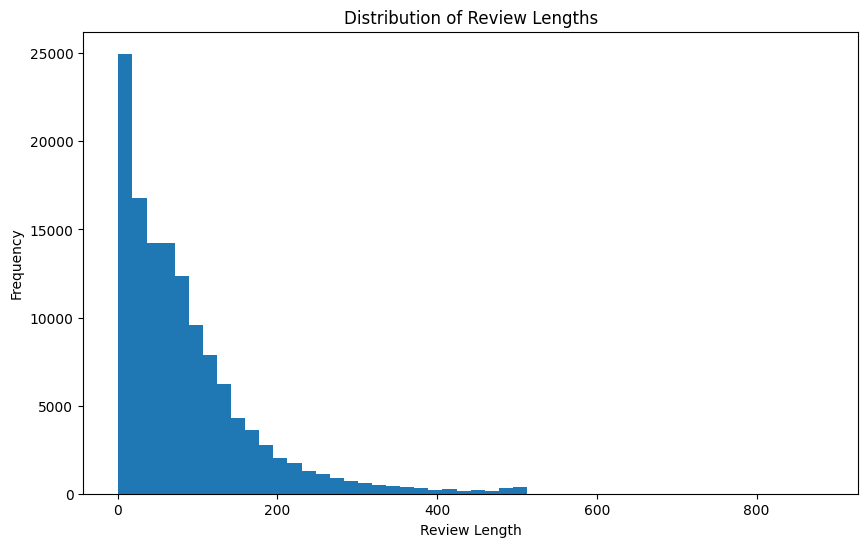

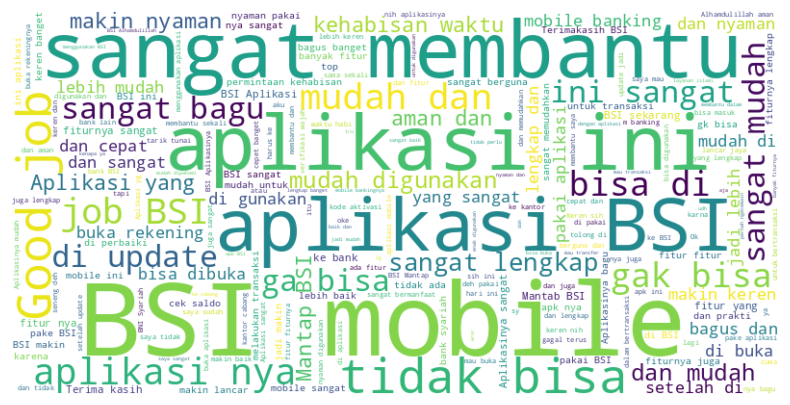

In [ ]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

plt.figure(figsize=(10, 6))
plt.hist(df['content_length'], bins=50)
plt.xlabel("Review Length")
plt.ylabel("Frequency")
plt.title("Distribution of Review Lengths")
plt.show()

all_reviews = ' '.join([str(content) for content in df['content'].dropna()])

wordcloud = WordCloud(width=800, height=400, background_color='white').generate(all_reviews)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.show()

## Pre-processing teks

In [ ]:
import string
import re

def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = text.translate(str.maketrans('', '', string.digits))
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
    text = text.lower()
    return text

df['cleaned_content'] = df['content'].apply(clean_text)

print("First 5 rows of the DataFrame with cleaned content:")
display(df[['content', 'cleaned_content']].head())

First 5 rows of the DataFrame with cleaned content:


,content,cleaned_content
0,mantap,mantap
1,benci bgt BSI banyak errornya banyak ga bisany...,benci bgt bsi banyak errornya banyak ga bisany...
2,Tolong segera diperbaiki sudah beberapa hari i...,tolong segera diperbaiki sudah beberapa hari i...
3,bsi mobile lebih oke,bsi mobile lebih oke
4,aplikasi error,aplikasi error


In [ ]:
import nltk
nltk.download('punkt_tab')

from nltk.tokenize import word_tokenize

df['nltk_tokens'] = df['cleaned_content'].apply(word_tokenize)

display(df[['cleaned_content', 'nltk_tokens']].head())

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


,cleaned_content,nltk_tokens
0,mantap,[mantap]
1,benci bgt bsi banyak errornya banyak ga bisany...,"[benci, bgt, bsi, banyak, errornya, banyak, ga..."
2,tolong segera diperbaiki sudah beberapa hari i...,"[tolong, segera, diperbaiki, sudah, beberapa, ..."
3,bsi mobile lebih oke,"[bsi, mobile, lebih, oke]"
4,aplikasi error,"[aplikasi, error]"


In [ ]:
from nltk.corpus import stopwords
import nltk

try:
    stopwords.words('indonesian')
except LookupError:
    nltk.download('stopwords')

indonesian_stopwords = set(stopwords.words('indonesian'))

def remove_stopwords(tokens):
    return [word for word in tokens if word not in indonesian_stopwords]

df['nltk_tokens_no_stopwords'] = df['nltk_tokens'].apply(remove_stopwords)

display(df[['nltk_tokens', 'nltk_tokens_no_stopwords']].head())

,nltk_tokens,nltk_tokens_no_stopwords
0,[mantap],[mantap]
1,"[benci, bgt, bsi, banyak, errornya, banyak, ga...","[benci, bgt, bsi, errornya, ga, bisanya, berus..."
2,"[tolong, segera, diperbaiki, sudah, beberapa, ...","[tolong, diperbaiki, transaksi, eror, keluhann..."
3,"[bsi, mobile, lebih, oke]","[bsi, mobile, oke]"
4,"[aplikasi, error]","[aplikasi, error]"


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

df['nltk_tokens_no_stopwords_str'] = df['nltk_tokens_no_stopwords'].apply(lambda tokens: ' '.join(map(str, tokens)))

tfidf_vectorizer = TfidfVectorizer()

tfidf_matrix = tfidf_vectorizer.fit_transform(df['nltk_tokens_no_stopwords_str'])

print("TF-IDF matrix shape:", tfidf_matrix.shape)

TF-IDF matrix shape: (128607, 46006)


## Pre-processing teks dengan Sastrawi

In [ ]:
import string
import re

def clean_text_sastrawi(text):
    if not isinstance(text, str):
        return ""
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = text.translate(str.maketrans('', '', string.digits))
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
    text = text.lower()
    return text

df['cleaned_content_sastrawi'] = df['content'].apply(clean_text_sastrawi)

print("First 5 rows of the DataFrame with original and cleaned content using Sastrawi (text cleaning part):")
display(df[['content', 'cleaned_content_sastrawi']].head())

First 5 rows of the DataFrame with original and cleaned content using Sastrawi (text cleaning part):


,content,cleaned_content_sastrawi
0,mantap,mantap
1,benci bgt BSI banyak errornya banyak ga bisany...,benci bgt bsi banyak errornya banyak ga bisany...
2,Tolong segera diperbaiki sudah beberapa hari i...,tolong segera diperbaiki sudah beberapa hari i...
3,bsi mobile lebih oke,bsi mobile lebih oke
4,aplikasi error,aplikasi error


In [ ]:
import nltk
nltk.download('punkt')
from nltk.tokenize import word_tokenize

def sastrawi_tokenize(text):
    if isinstance(text, str):
        return word_tokenize(text)
    return []

df['sastrawi_tokens'] = df['cleaned_content_sastrawi'].apply(sastrawi_tokenize)

display(df[['cleaned_content_sastrawi', 'sastrawi_tokens']].head())

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


,cleaned_content_sastrawi,sastrawi_tokens
0,mantap,[mantap]
1,benci bgt bsi banyak errornya banyak ga bisany...,"[benci, bgt, bsi, banyak, errornya, banyak, ga..."
2,tolong segera diperbaiki sudah beberapa hari i...,"[tolong, segera, diperbaiki, sudah, beberapa, ..."
3,bsi mobile lebih oke,"[bsi, mobile, lebih, oke]"
4,aplikasi error,"[aplikasi, error]"


In [ ]:
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

factory = StopWordRemoverFactory()
stopword_remover = factory.create_stop_word_remover()

In [ ]:
def remove_sastrawi_stopwords(tokens):
    if isinstance(tokens, list):
        return [stopword_remover.remove(str(token)) for token in tokens if isinstance(token, str)]
    return []

df['sastrawi_tokens_no_stopwords'] = df['sastrawi_tokens'].apply(remove_sastrawi_stopwords)

display(df[['sastrawi_tokens', 'sastrawi_tokens_no_stopwords']].head())

,sastrawi_tokens,sastrawi_tokens_no_stopwords
0,[mantap],[mantap]
1,"[benci, bgt, bsi, banyak, errornya, banyak, ga...","[benci, bgt, bsi, banyak, errornya, banyak, ga..."
2,"[tolong, segera, diperbaiki, sudah, beberapa, ...","[, segera, diperbaiki, , beberapa, hari, , mau..."
3,"[bsi, mobile, lebih, oke]","[bsi, mobile, lebih, oke]"
4,"[aplikasi, error]","[aplikasi, error]"


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

df['sastrawi_tokens_no_stopwords_str'] = df['sastrawi_tokens_no_stopwords'].apply(lambda tokens: ' '.join(map(str, tokens)))

tfidf_vectorizer_sastrawi = TfidfVectorizer()

tfidf_matrix_sastrawi = tfidf_vectorizer_sastrawi.fit_transform(df['sastrawi_tokens_no_stopwords_str'])

print("TF-IDF matrix shape (Sastrawi):", tfidf_matrix_sastrawi.shape)

TF-IDF matrix shape (Sastrawi): (128607, 46475)


## Visualisasi dan Evaluasi

Memulai reduksi dimensi dengan TruncatedSVD...
Reduksi dimensi selesai.
Membuat visualisasi cluster...


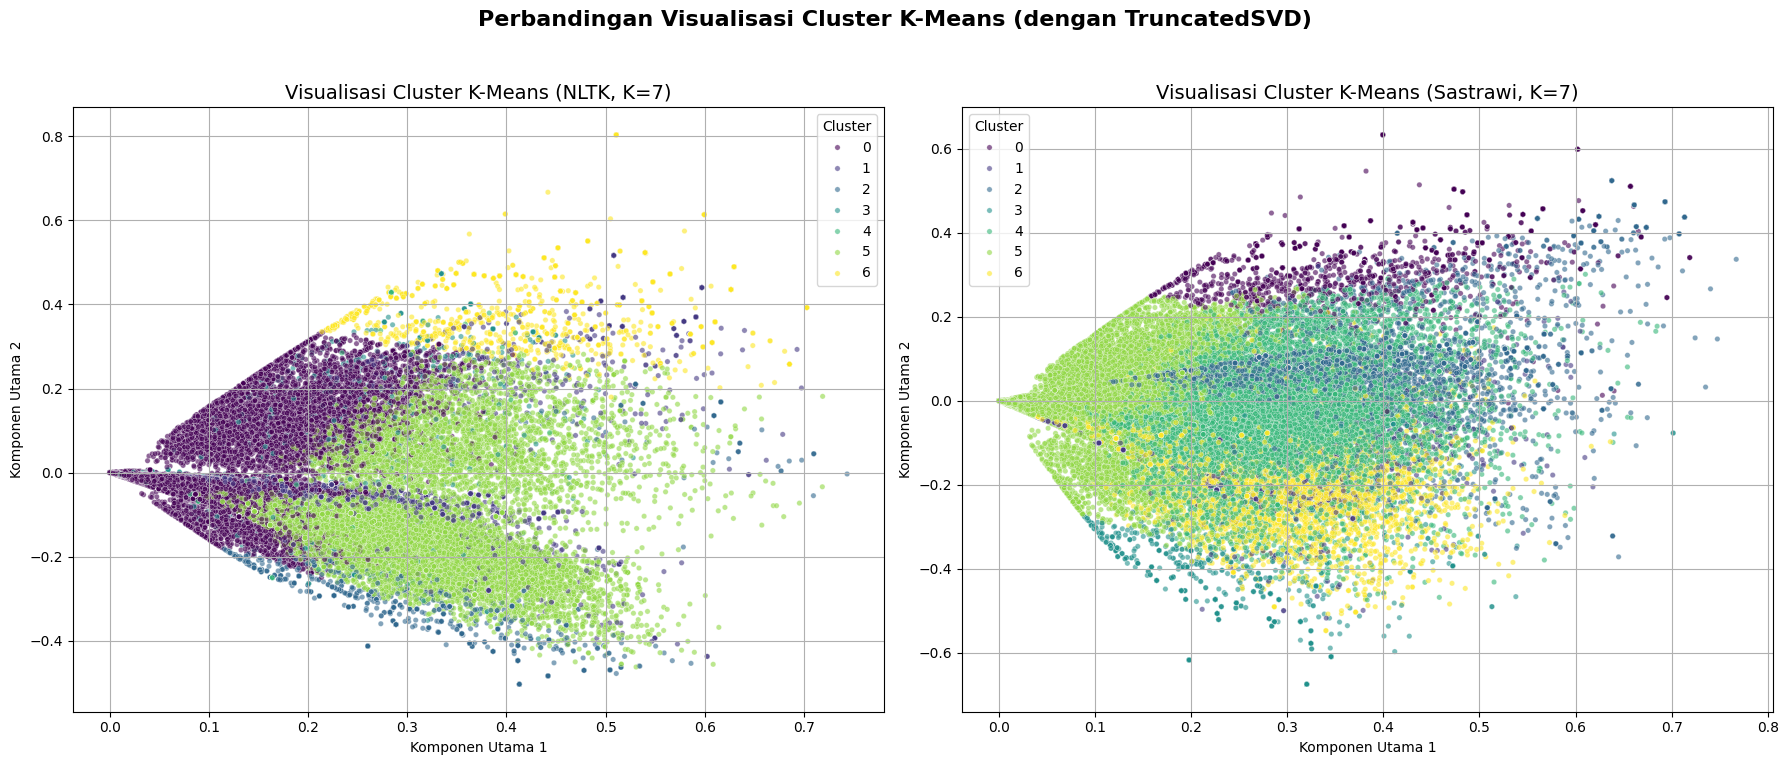

In [ ]:
from sklearn.decomposition import TruncatedSVD  # Ganti PCA dengan TruncatedSVD
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.cluster import KMeans

print("Memulai reduksi dimensi dengan TruncatedSVD...")

svd_nltk = TruncatedSVD(n_components=2, random_state=42)
tfidf_svd_nltk = svd_nltk.fit_transform(tfidf_matrix)

svd_sastrawi = TruncatedSVD(n_components=2, random_state=42)
tfidf_svd_sastrawi = svd_sastrawi.fit_transform(tfidf_matrix_sastrawi)

print("Reduksi dimensi selesai.")

kmeans_nltk_final = KMeans(n_clusters=7, random_state=42, n_init=10)
df['kmeans_cluster_nltk'] = kmeans_nltk_final.fit_predict(tfidf_matrix)

kmeans_sastrawi_final = KMeans(n_clusters=7, random_state=42, n_init=10)
df['kmeans_cluster_sastrawi'] = kmeans_sastrawi_final.fit_predict(tfidf_matrix_sastrawi)

df_plot_nltk = pd.DataFrame(tfidf_svd_nltk, columns=['Component 1', 'Component 2'])
df_plot_nltk['cluster'] = df['kmeans_cluster_nltk']

df_plot_sastrawi = pd.DataFrame(tfidf_svd_sastrawi, columns=['Component 1', 'Component 2'])
df_plot_sastrawi['cluster'] = df['kmeans_cluster_sastrawi']

print("Membuat visualisasi cluster...")
plt.figure(figsize=(18, 8))

plt.subplot(1, 2, 1)
sns.scatterplot(data=df_plot_nltk, x='Component 1', y='Component 2', hue='cluster', palette='viridis', s=15, alpha=0.6)
plt.title('Visualisasi Cluster K-Means (NLTK, K=7)', fontsize=14)
plt.xlabel('Komponen Utama 1')
plt.ylabel('Komponen Utama 2')
plt.legend(title='Cluster')
plt.grid(True)

plt.subplot(1, 2, 2)
sns.scatterplot(data=df_plot_sastrawi, x='Component 1', y='Component 2', hue='cluster', palette='viridis', s=15, alpha=0.6)
plt.title('Visualisasi Cluster K-Means (Sastrawi, K=7)', fontsize=14)
plt.xlabel('Komponen Utama 1')
plt.ylabel('Komponen Utama 2')
plt.legend(title='Cluster')
plt.grid(True)

plt.suptitle('Perbandingan Visualisasi Cluster K-Means (dengan TruncatedSVD)', fontsize=16, fontweight='bold')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

Membuat visualisasi top words untuk hasil NLTK...


/tmp/ipython-input-1428921180.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10_weights, y=top_10_terms, ax=axes[i], palette='viridis')
/tmp/ipython-input-1428921180.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10_weights, y=top_10_terms, ax=axes[i], palette='viridis')
/tmp/ipython-input-1428921180.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10_weights, y=top_10_terms, ax=axes[i], palette='viridis')
/tmp/ipython-input-1428921180.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is depr

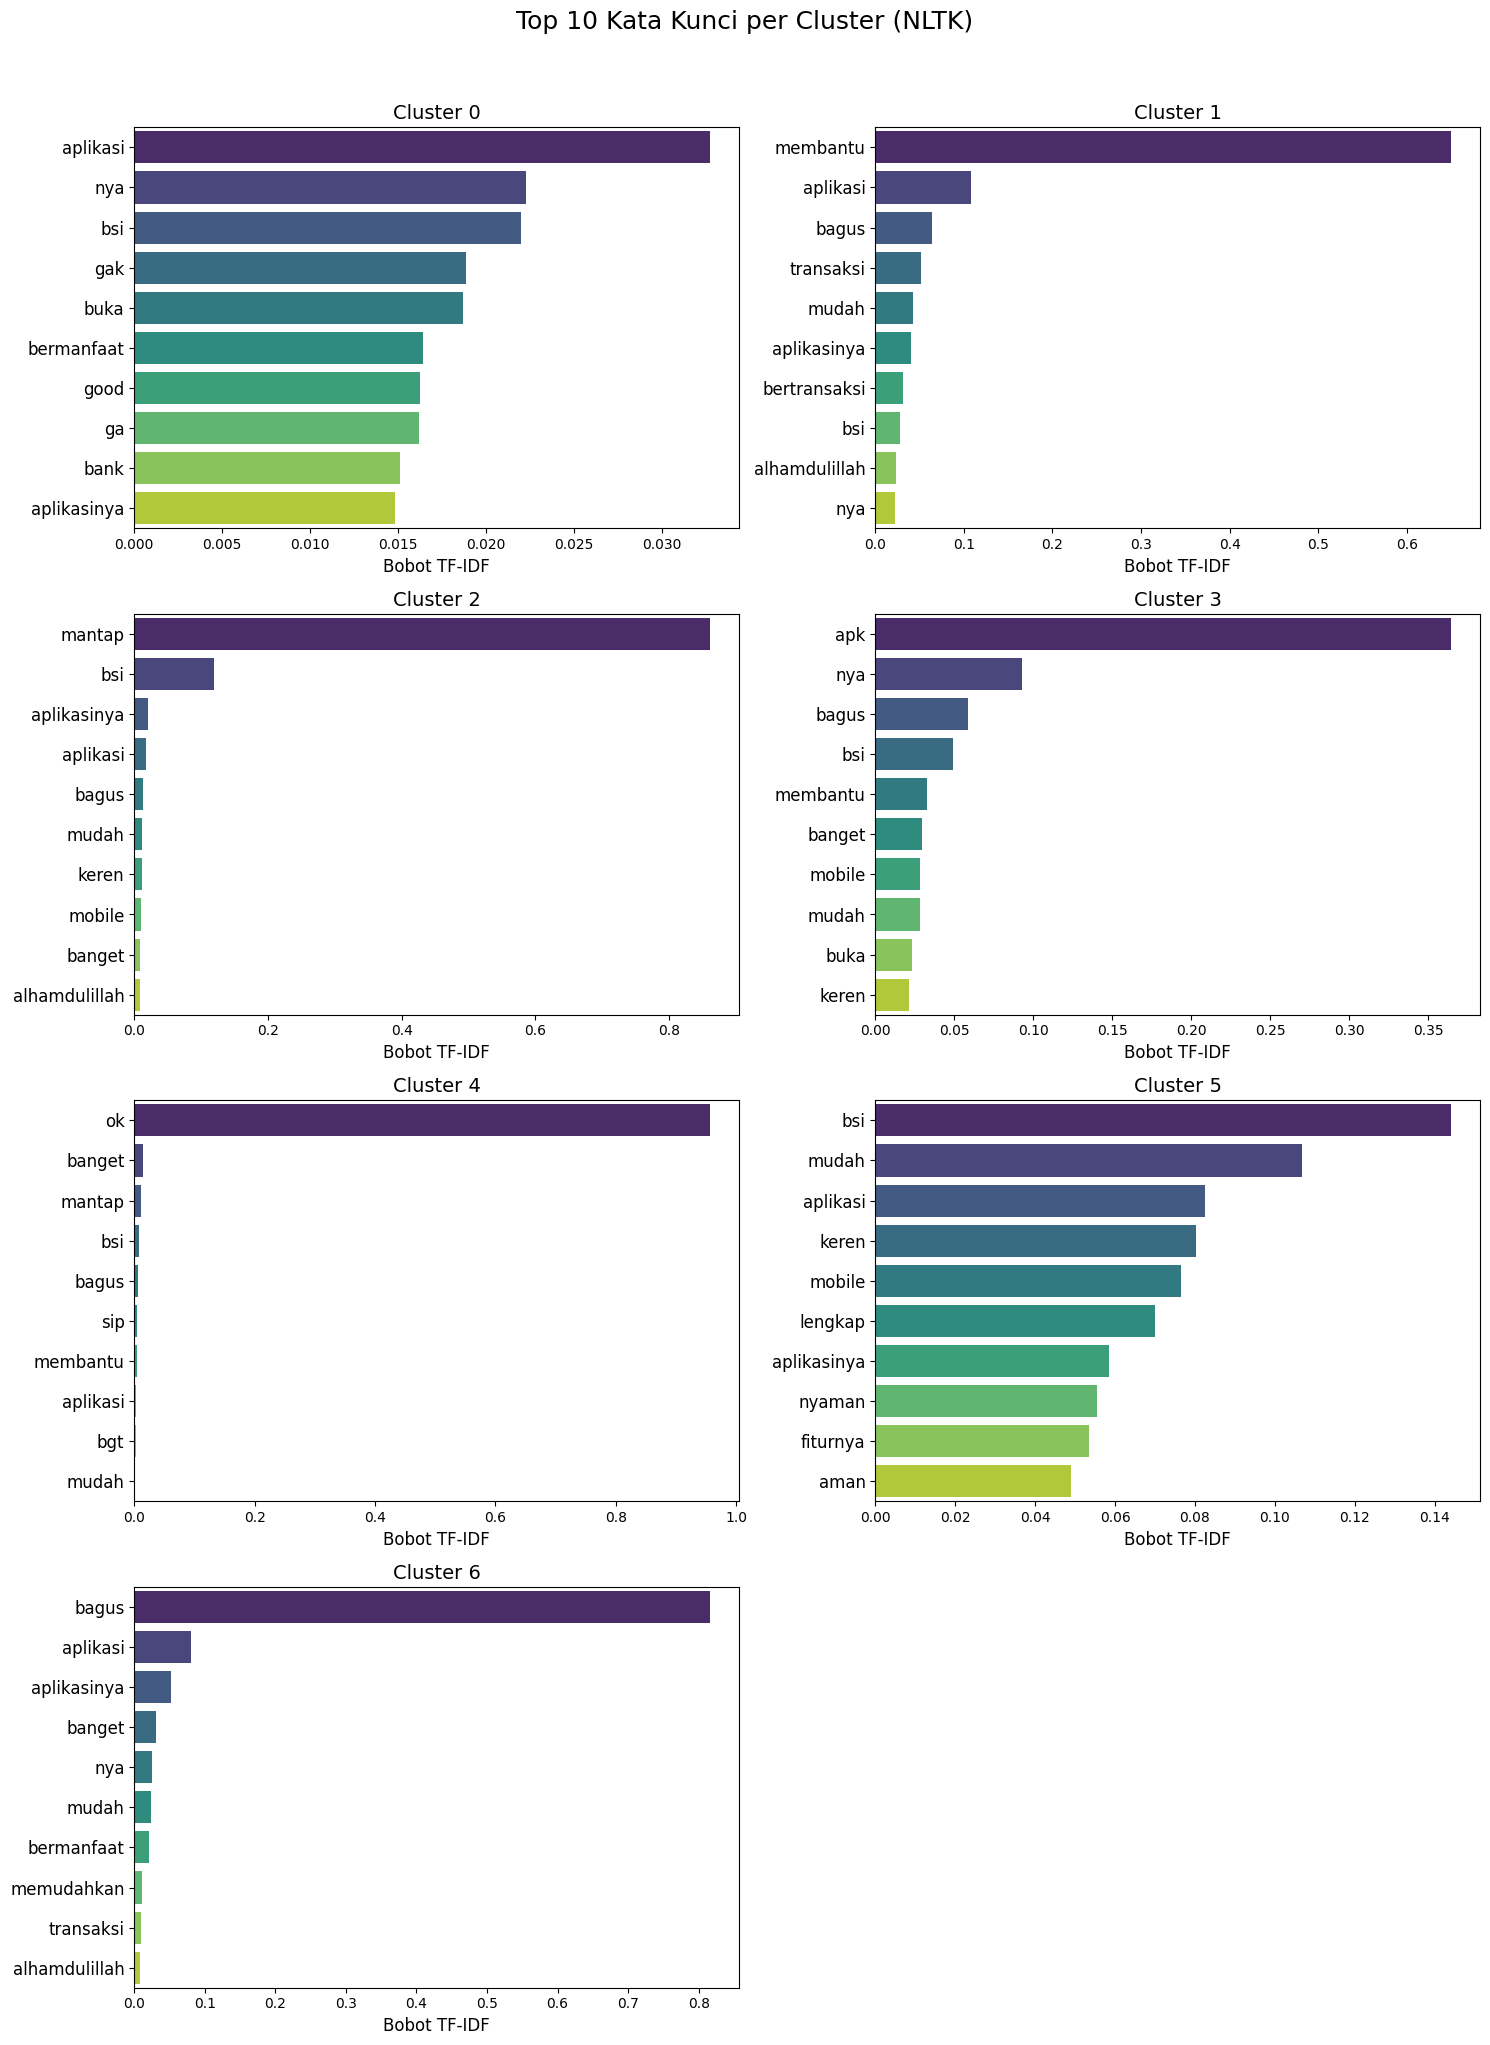


Membuat visualisasi top words untuk hasil Sastrawi...


/tmp/ipython-input-1428921180.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10_weights, y=top_10_terms, ax=axes[i], palette='viridis')
/tmp/ipython-input-1428921180.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10_weights, y=top_10_terms, ax=axes[i], palette='viridis')
/tmp/ipython-input-1428921180.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10_weights, y=top_10_terms, ax=axes[i], palette='viridis')
/tmp/ipython-input-1428921180.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is depr

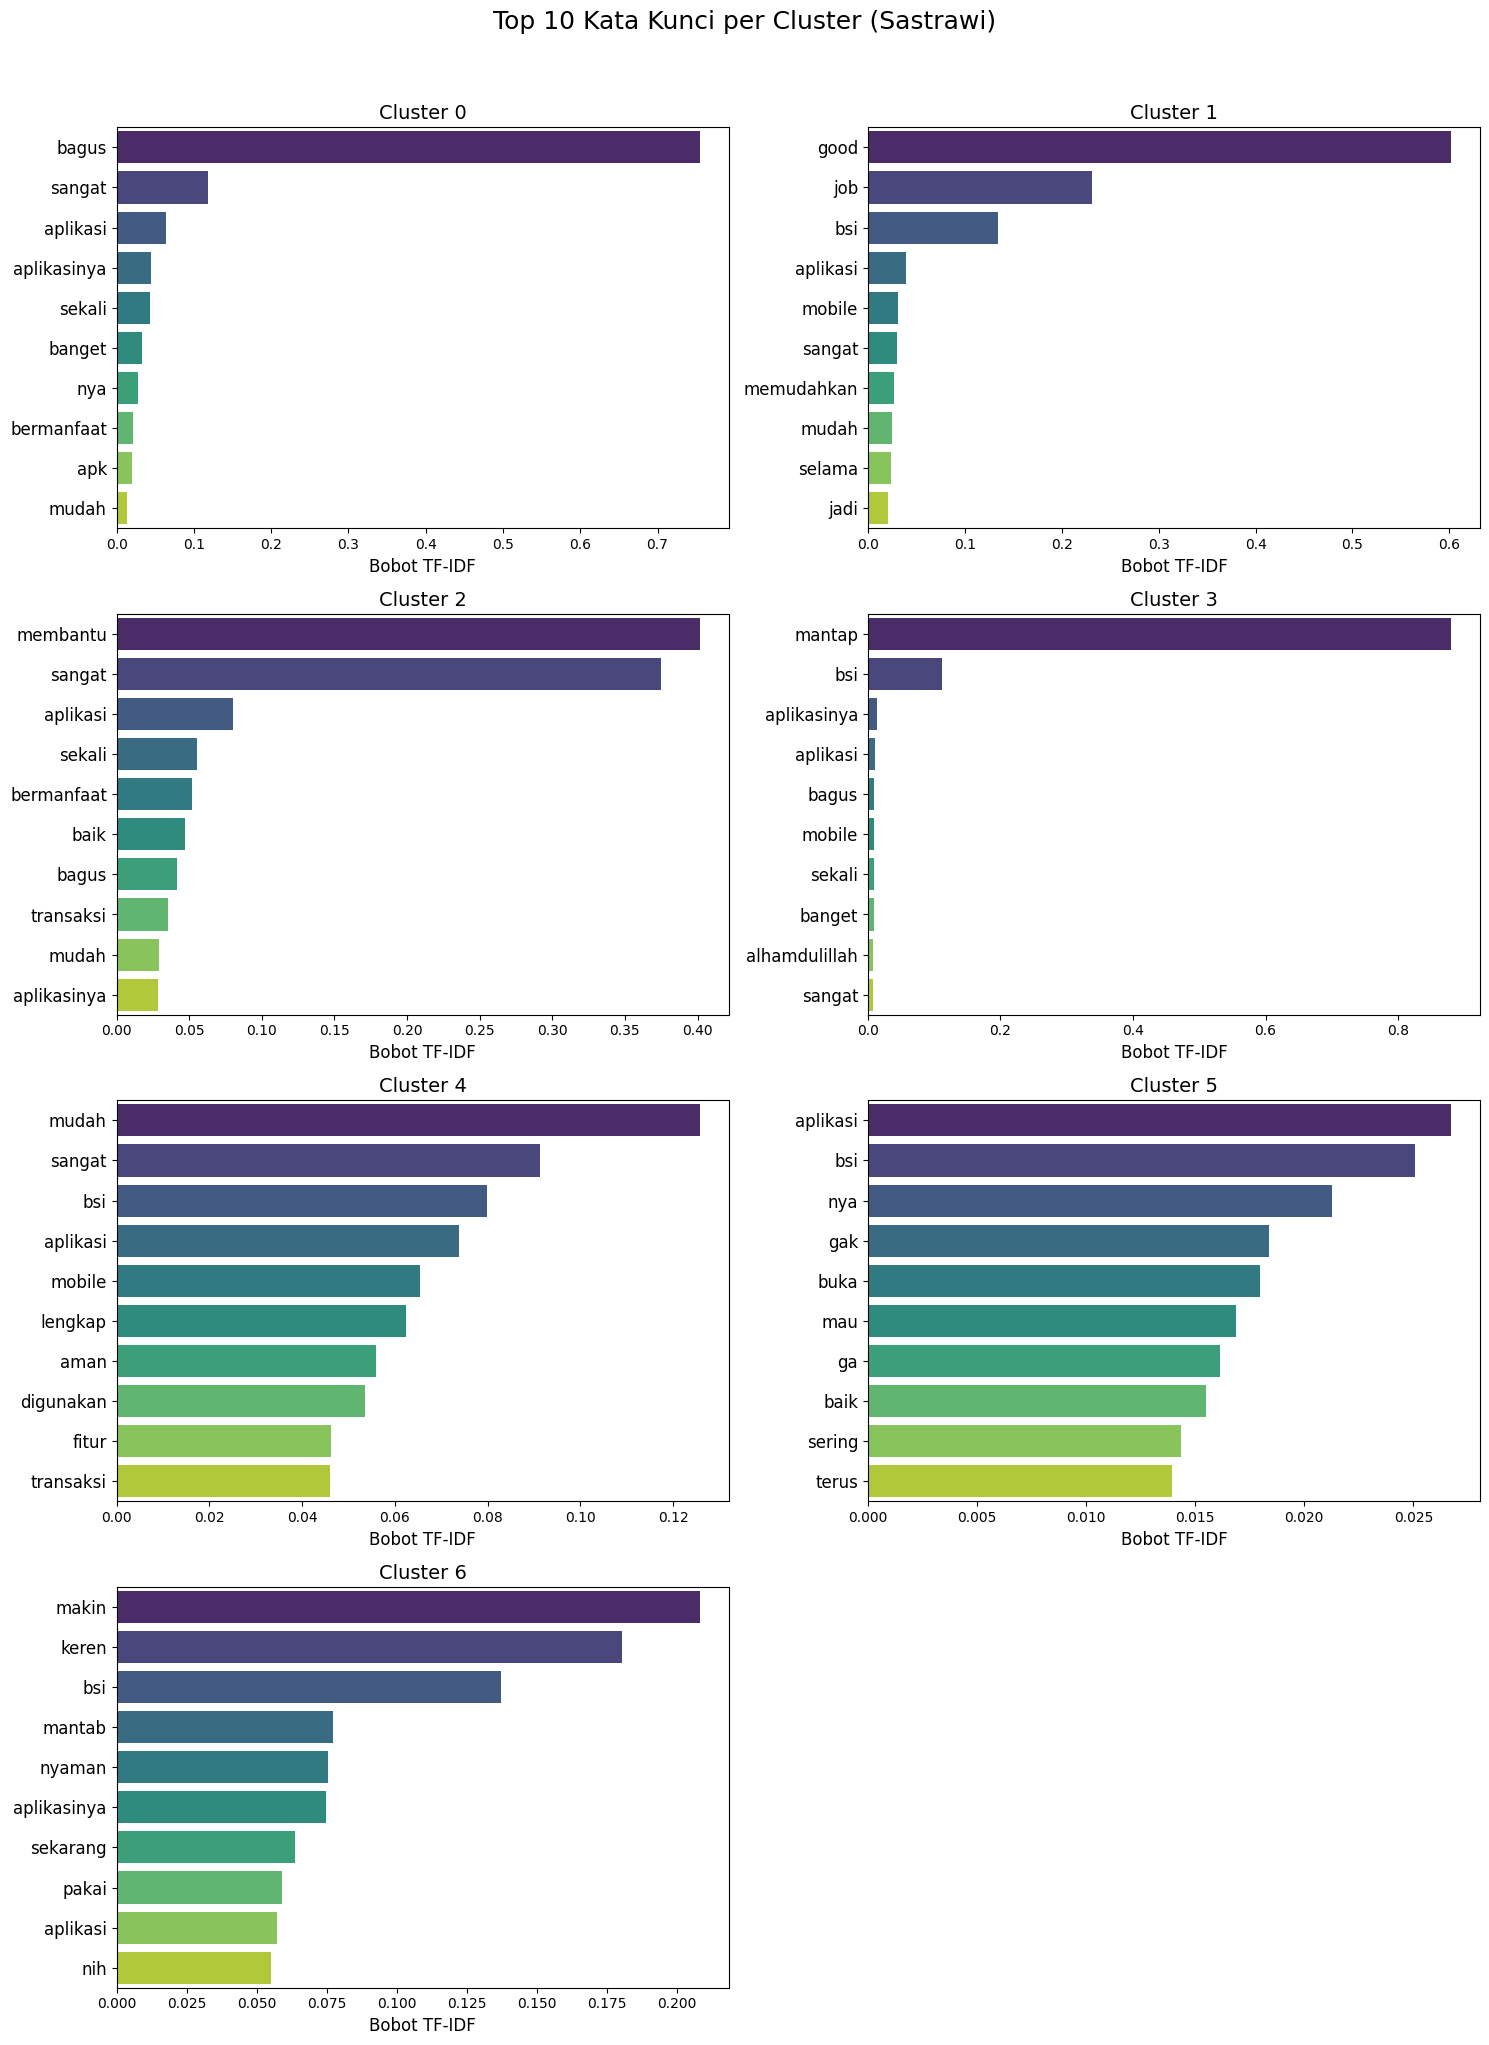

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

def plot_top_words_per_cluster(kmeans_model, tfidf_vectorizer, title_prefix):
    """Membuat diagram batang untuk top 10 words di setiap cluster."""

    terms = tfidf_vectorizer.get_feature_names_out()
    order_centroids = kmeans_model.cluster_centers_.argsort()[:, ::-1]

    fig, axes = plt.subplots(4, 2, figsize=(15, 20))
    axes = axes.flatten()

    for i in range(kmeans_model.n_clusters):
        top_10_indices = order_centroids[i, :10]
        top_10_terms = [terms[ind] for ind in top_10_indices]
        top_10_weights = kmeans_model.cluster_centers_[i, top_10_indices]

        sns.barplot(x=top_10_weights, y=top_10_terms, ax=axes[i], palette='viridis')
        axes[i].set_title(f'Cluster {i}', fontsize=14)
        axes[i].set_xlabel('Bobot TF-IDF', fontsize=12)
        axes[i].tick_params(axis='y', labelsize=12)

    if kmeans_model.n_clusters < len(axes):
        for j in range(kmeans_model.n_clusters, len(axes)):
            fig.delaxes(axes[j])

    plt.suptitle(f'Top 10 Kata Kunci per Cluster ({title_prefix})', fontsize=18, y=1.02)
    plt.tight_layout()
    plt.show()

print("Membuat visualisasi top words untuk hasil NLTK...")
plot_top_words_per_cluster(kmeans_nltk_final, tfidf_vectorizer, 'NLTK')


print("\nMembuat visualisasi top words untuk hasil Sastrawi...")
plot_top_words_per_cluster(kmeans_sastrawi_final, tfidf_vectorizer_sastrawi, 'Sastrawi')

## Modeling clustering

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

n_clusters_list = [3, 5, 7]
silhouette_scores = []

for n_clusters in n_clusters_list:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    kmeans.fit(tfidf_matrix)
    cluster_labels = kmeans.predict(tfidf_matrix)
    silhouette_avg = silhouette_score(tfidf_matrix, cluster_labels)
    silhouette_scores.append(silhouette_avg)
    print(f"Silhouette score for K={n_clusters}: {silhouette_avg}")

Silhouette score for K=3: 0.027028627410738564
Silhouette score for K=5: 0.03748636252506381
Silhouette score for K=7: 0.04938392690467158


## Modeling clustering dengan Sastrawi

In [ ]:
# Use the same n_clusters_list as before
n_clusters_list = [3, 5, 7]
sastrawi_silhouette_scores = []

for n_clusters in n_clusters_list:
    kmeans_sastrawi = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    kmeans_sastrawi.fit(tfidf_matrix_sastrawi)
    cluster_labels_sastrawi = kmeans_sastrawi.predict(tfidf_matrix_sastrawi)
    silhouette_avg_sastrawi = silhouette_score(tfidf_matrix_sastrawi, cluster_labels_sastrawi)
    sastrawi_silhouette_scores.append(silhouette_avg_sastrawi)
    print(f"Silhouette score for K={n_clusters} (Sastrawi): {silhouette_avg_sastrawi}")

Silhouette score for K=3 (Sastrawi): 0.022504949432673338
Silhouette score for K=5 (Sastrawi): 0.0325331915086436
Silhouette score for K=7 (Sastrawi): 0.03742187168732601
